## Importation des biblio





In [32]:
import sys, platform
import torch, torchvision, cv2
import numpy as np
import pandas as pd
import matplotlib

## les versions

In [33]:

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("CUDA (torch):", torch.version.cuda)
print("GPU dispo   :", torch.cuda.is_available())

PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130
CUDA (torch): 13.0
GPU dispo   : True


## Afficher etat de GPU

In [34]:
!nvidia-smi

Fri Oct 30 14:54:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### graine alEatoire et fonction d’affichage

In [35]:
import os
import random
import shutil
import pathlib
import yaml
from collections import Counter
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
print("Device :", device)

def show(img, title=""):
    """Affiche une image OpenCV (BGR) avec Matplotlib (RGB)."""
    plt.figure(figsize=(7, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=8)
    plt.axis("off")
    plt.show()

Device : cuda


## Télécharger le dataset depuis Kaggle

In [36]:
!pip install -q kagglehub
import kagglehub

dataset_path = pathlib.Path(
    kagglehub.dataset_download("ashfakyeafi/road-vehicle-images-dataset")
)
print("Dataset telechargE dans :", dataset_path)
print("Contenu :", os.listdir(dataset_path))

Using Colab cache for faster access to the 'road-vehicle-images-dataset' dataset.
Dataset telechargE dans : /kaggle/input/road-vehicle-images-dataset
Contenu : ['trafic_data']


## Exploration

## afficher l’arborescence du dataset

In [37]:
for root, dirs, files in os.walk(dataset_path):
    parts = pathlib.Path(root).relative_to(dataset_path).parts
    if len(parts) <= 4:
        print("  " * len(parts) + f"{os.path.basename(root)}/  ({len(files)} fichiers)")

road-vehicle-images-dataset/  (0 fichiers)
  trafic_data/  (1 fichiers)
    valid/  (1 fichiers)
      labels/  (300 fichiers)
      images/  (300 fichiers)
    train/  (1 fichiers)
      labels/  (2704 fichiers)
      images/  (2704 fichiers)


## Identifier  les autre fichiers

In [38]:
SRC = dataset_path / "trafic_data" if (dataset_path / "trafic_data").is_dir() else dataset_path
print("Dossier source (lecture seule) :", SRC)

print("\nExtensions presentes :")
for ext, n in Counter(p.suffix.lower() for p in SRC.rglob("*") if p.is_file()).most_common():
    print(f"  {ext} : {n}")

print("\nFichiers hors images/labels :")
for folder in [SRC, SRC / "train", SRC / "valid"]:
    for f in folder.iterdir():
        if f.is_file():
            print(f"  {f.relative_to(SRC)}  ({f.stat().st_size / 1024:.1f} KB)")

Dossier source (lecture seule) : /kaggle/input/road-vehicle-images-dataset/trafic_data

Extensions presentes :
  .txt : 3004
  .jpg : 3004
  .cache : 2
  .yaml : 1

Fichiers hors images/labels :
  data_1.yaml  (0.3 KB)
  train/labels.cache  (1045.8 KB)
  valid/labels.cache  (118.9 KB)


### coper le dataset  sans cashe

In [39]:
WORK_DIR = pathlib.Path("/content/dataset")

if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)

shutil.copytree(SRC, WORK_DIR, ignore=shutil.ignore_patterns("*.cache"))
base_dir = WORK_DIR
splits = ["train", "valid"]

print("Copie cree dans :", base_dir)
for s in splits:
    n_img = len(list((base_dir / s / "images").iterdir()))
    n_lbl = len(list((base_dir / s / "labels").iterdir()))
    print(f"{s}: {n_img} images | {n_lbl} labels")

Copie cree dans : /content/dataset
train: 2704 images | 2704 labels
valid: 300 images | 300 labels


### verifier  images / labels

In [40]:
def check_split(base_dir, split):
    img_dir = base_dir / split / "images"
    lbl_dir = base_dir / split / "labels"

    img_stems = {f.stem: f for f in img_dir.iterdir() if f.suffix.lower() in IMG_EXT}
    lbl_stems = {f.stem: f for f in lbl_dir.iterdir() if f.suffix == ".txt"}

    labels_sans_image = sorted(set(lbl_stems) - set(img_stems))
    images_sans_label = sorted(set(img_stems) - set(lbl_stems))
    labels_vides = sorted(s for s, f in lbl_stems.items() if f.stat().st_size == 0)

    print(f" {split}")
    print(f"Images            : {len(img_stems)}")
    print(f"Labels            : {len(lbl_stems)}")
    print(f"Labels sans image : {len(labels_sans_image)}")
    print(f"Images sans label : {len(images_sans_label)}")
    print(f"Labels vides      : {len(labels_vides)}")
    return labels_sans_image, images_sans_label, labels_vides

results = {s: check_split(base_dir, s) for s in splits}

 train
Images            : 2704
Labels            : 2704
Labels sans image : 0
Images sans label : 0
Labels vides      : 2
 valid
Images            : 300
Labels            : 300
Labels sans image : 0
Images sans label : 0
Labels vides      : 0


##les labels vides

Labels vides (train) : ['01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93', '231_jpg.rf.42292592b7fed42abf94d9624eda3fa5']


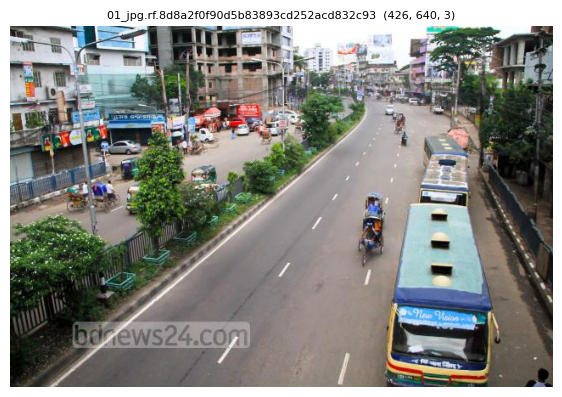

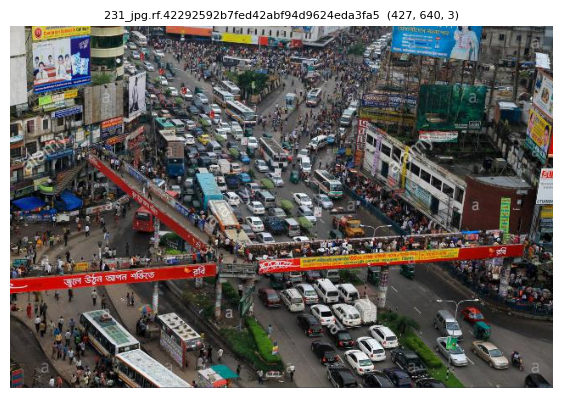

In [41]:
_, _, vides_train = results["train"]
print("Labels vides (train) :", vides_train)

for stem in vides_train:
    img_path = next(f for f in (base_dir / "train" / "images").iterdir()
                    if f.stem == stem and f.suffix.lower() in IMG_EXT)
    img = cv2.imread(str(img_path))
    show(img, f"{stem}  {img.shape}")

### Supprimer les labels vides et leurs images

In [42]:
removed = []
for split in splits:
    lbl_dir = base_dir / split / "labels"
    img_dir = base_dir / split / "images"
    for lbl in lbl_dir.glob("*.txt"):
        if lbl.stat().st_size == 0:
            for img in img_dir.iterdir():
                if img.stem == lbl.stem and img.suffix.lower() in IMG_EXT:
                    img.unlink()
            lbl.unlink()
            removed.append((split, lbl.stem))

print(f"{len(removed)} paires (image + label) supprimées :")
for split, stem in removed:
    print("  ", split, stem)

2 paires (image + label) supprimées :
   train 231_jpg.rf.42292592b7fed42abf94d9624eda3fa5
   train 01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93


## Vérifier le résultat



In [43]:
for split in splits:
    imgs = [f for f in (base_dir / split / "images").iterdir() if f.suffix.lower() in IMG_EXT]
    lbls = list((base_dir / split / "labels").glob("*.txt"))
    vides = [f for f in lbls if f.stat().st_size == 0]
    print(f"{split}: {len(imgs)} images | {len(lbls)} labels | {len(vides)} vides")

train: 2702 images | 2702 labels | 0 vides
valid: 300 images | 300 labels | 0 vides


### Lire le fichier de configuration

In [44]:
cfg_path = base_dir / "data_1.yaml"
with open(cfg_path) as f:
    cfg = yaml.safe_load(f)

print(yaml.dump(cfg, allow_unicode=True))
names = cfg["names"]
names_list = list(names.values()) if isinstance(names, dict) else list(names)
print("Nombre de classes (nc) :", cfg.get("nc"))
print("Nombre de noms         :", len(names_list))
print("Classes                :", names_list)
assert cfg.get("nc", len(names_list)) == len(names_list), "nc ne correspond pas a names "

names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow
nc: 21
train: ../train/images
val: ../valid/images

Nombre de classes (nc) : 21
Nombre de noms         : 21
Classes                : ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']


### data.yaml avec des chemins corrects

In [45]:
data_yaml = {
    "path": str(base_dir),
    "train": "train/images",
    "val": "valid/images",
    "nc": len(names_list),
    "names": names_list,
}

DATA_YAML = base_dir / "data.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_yaml, f, allow_unicode=True, sort_keys=False)

print("Fichier ecrit :", DATA_YAML)
print(DATA_YAML.read_text())

Fichier ecrit : /content/dataset/data.yaml
path: /content/dataset
train: train/images
val: valid/images
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow



## creer le jeu de test (405 images)

In [46]:
import torch
from torch.utils.data import random_split

N_TEST = 405

train_img_dir = base_dir / "train" / "images"
train_lbl_dir = base_dir / "train" / "labels"


img_map = {f.stem: f for f in train_img_dir.iterdir() if f.suffix.lower() in IMG_EXT}
stems = sorted(img_map)
print("Images dans train avant séparation :", len(stems))


assert len(stems) == 2702, f"Attendu 2702 images dans train, trouvé {len(stems)}. Relance les cellules 7 et 10 pour repartir d'une copie propre."


g = torch.Generator().manual_seed(42)
train_subset, test_subset = random_split(
    stems, [len(stems) - N_TEST, N_TEST], generator=g
)
test_stems = [stems[i] for i in test_subset.indices]

print("Train :", len(train_subset), "| Test :", len(test_stems))


test_img_dir = base_dir / "test" / "images"
test_lbl_dir = base_dir / "test" / "labels"
test_img_dir.mkdir(parents=True, exist_ok=True)
test_lbl_dir.mkdir(parents=True, exist_ok=True)


for stem in test_stems:
    shutil.move(str(img_map[stem]), str(test_img_dir / img_map[stem].name))
    shutil.move(str(train_lbl_dir / f"{stem}.txt"), str(test_lbl_dir / f"{stem}.txt"))

print(f"{len(test_stems)} paires déplacées vers test/")

Images dans train avant séparation : 2702
Train : 2297 | Test : 405
405 paires déplacées vers test/


## collecter

In [47]:
from pathlib import Path

def collect(base_dir, split):

    img_dir = Path(base_dir) / split / "images"
    lbl_dir = Path(base_dir) / split / "labels"
    return {
        "images": sorted(str(p) for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXT),
        "labels": sorted(str(p) for p in lbl_dir.glob("*.txt")),
    }

splits = [s for s in ["train", "valid", "test"] if (base_dir / s).is_dir()]
data = {s: collect(base_dir, s) for s in splits}
for s in splits:
    print(s, "->", len(data[s]["images"]), "images |", len(data[s]["labels"]), "labels")

train -> 2297 images | 2297 labels
valid -> 300 images | 300 labels
test -> 405 images | 405 labels


## differnce entre image et labels

In [48]:
def image_label_diff(data):
    images = {Path(p).stem for p in data["images"]}
    labels = {Path(p).stem for p in data["labels"]}
    img_only = images - labels
    lbl_only = labels - images
    print("Images sans label :", len(img_only), sorted(img_only)[:5])
    print("Labels sans image :", len(lbl_only), sorted(lbl_only)[:5])
    return img_only, lbl_only

for s in splits:
    print(f"--- {s} ---")
    image_label_diff(data[s])

--- train ---
Images sans label : 0 []
Labels sans image : 0 []
--- valid ---
Images sans label : 0 []
Labels sans image : 0 []
--- test ---
Images sans label : 0 []
Labels sans image : 0 []


## verifier les octecs des images

In [49]:
from PIL import Image

def check_images_bytes(image_paths):
    """Décode complètement chaque image avec .load() ; retourne la liste des fichiers corrompus."""
    corrompues = []
    for p in image_paths:
        try:
            with Image.open(p) as im:
                im.load()
        except Exception as e:
            corrompues.append((p, repr(e)))
    return corrompues

for s in splits:
    bad = check_images_bytes(data[s]["images"])
    print(f"{s}: {len(data[s]['images'])} images vérifiées | {len(bad)} corrompues")
    for p, e in bad[:5]:
        print("   ", Path(p).name, e)

train: 2297 images vérifiées | 0 corrompues
valid: 300 images vérifiées | 0 corrompues
test: 405 images vérifiées | 0 corrompues


### vwrifir le centenu de labels

In [50]:
def check_labels_content(label_paths, nc=21):
    invalides = []
    for p in label_paths:
        for i, line in enumerate(Path(p).read_text().splitlines(), 1):
            if not line.strip():
                continue
            parts = line.split()
            try:
                ok = (len(parts) == 5
                      and int(parts[0]) in range(nc)
                      and all(0.0 <= float(v) <= 1.0 for v in parts[1:]))
            except ValueError:
                ok = False
            if not ok:
                invalides.append((Path(p).name, i, line))
    return invalides

for s in splits:
    bad = check_labels_content(data[s]["labels"], nc=len(names_list))
    print(f"{s}: {len(bad)} lignes invalides")
    for b in bad[:5]:
        print("   ", b)

train: 0 lignes invalides
valid: 0 lignes invalides
test: 0 lignes invalides


### Vérifier que le dataset est pret

In [51]:
import pathlib, os
DATA_YAML = pathlib.Path("/content/dataset/data.yaml")
assert DATA_YAML.exists(), "data.yaml introuvable"
print(DATA_YAML.read_text())

path: /content/dataset
train: train/images
val: valid/images
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow



### Preparation de YOLOv9

In [52]:
%cd /content
!rm -rf yolov9
!git clone https://github.com/WongKinYiu/yolov9.git
%cd /content/yolov9

/content
Cloning into 'yolov9'...
remote: Enumerating objects: 781, done.
remote: Total 781 (delta 0), reused 0 (delta 0), pack-reused 781 (from 1)
Receiving objects: 100% (781/781), 3.27 MiB | 32.83 MiB/s, done.
Resolving deltas: 100% (330/330), done.
/content/yolov9


### installler les dependances

In [53]:
!pip install -q -r requirements.txt

### Corriger l’incompatibilite

In [54]:
p = pathlib.Path("/content/yolov9/utils/plots.py")
s = p.read_text()
s = s.replace("w, h = self.font.getsize(label)",
              "l, t, r, b = self.font.getbbox(label); w, h = r - l, b - t")
p.write_text(s)
print("Correction appliquée :", "getbbox" in p.read_text())

Correction appliquée : True


### Identifier le script, la configuration et les hyperparamètres

In [55]:
YOLO_DIR = pathlib.Path("/content/yolov9")
TRAIN_SCRIPT = YOLO_DIR / "train_dual.py"
MODEL_CFG    = YOLO_DIR / "models/detect/yolov9-c.yaml"
HYP_FILE     = YOLO_DIR / "data/hyps/hyp.scratch-high.yaml"

for nom, f in [("Script d'entraînement", TRAIN_SCRIPT),
               ("Architecture (cfg)", MODEL_CFG),
               ("Hyperparamètres", HYP_FILE)]:
    print(f"{nom:22s}: {f.relative_to(YOLO_DIR)}  existe={f.exists()}")

Script d'entraînement : train_dual.py  existe=True
Architecture (cfg)    : models/detect/yolov9-c.yaml  existe=True
Hyperparamètres       : data/hyps/hyp.scratch-high.yaml  existe=True


### Lire l architecture et les hyperparamètres

In [56]:
print("yolov9-c.yaml (début)")
print("\n".join(MODEL_CFG.read_text().splitlines()[:20]))
print("\n hyp.scratch-high.yaml ")
print(HYP_FILE.read_text())

yolov9-c.yaml (début)
# YOLOv9

# parameters
nc: 80  # number of classes
depth_multiple: 1.0  # model depth multiple
width_multiple: 1.0  # layer channel multiple
#activation: nn.LeakyReLU(0.1)
#activation: nn.ReLU()

# anchors
anchors: 3

# YOLOv9 backbone
backbone:
  [
   [-1, 1, Silence, []],  
   
   # conv down
   [-1, 1, Conv, [64, 3, 2]],  # 1-P1/2


 hyp.scratch-high.yaml 
lr0: 0.01  # initial learning rate (SGD=1E-2, Adam=1E-3)
lrf: 0.01  # final OneCycleLR learning rate (lr0 * lrf)
momentum: 0.937  # SGD momentum/Adam beta1
weight_decay: 0.0005  # optimizer weight decay 5e-4
warmup_epochs: 3.0  # warmup epochs (fractions ok)
warmup_momentum: 0.8  # warmup initial momentum
warmup_bias_lr: 0.1  # warmup initial bias lr
box: 7.5  # box loss gain
cls: 0.5  # cls loss gain
cls_pw: 1.0  # cls BCELoss positive_weight
obj: 0.7  # obj loss gain (scale with pixels)
obj_pw: 1.0  # obj BCELoss positive_weight
dfl: 1.5  # dfl loss gain
iou_t: 0.20  # IoU training threshold
anchor_t: 5.0  

## : Télécharger les poids préentraînés YOLOv9-C

In [57]:
!mkdir -p /content/yolov9/weights
!wget -q -O /content/yolov9/weights/yolov9-c.pt \
  https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt

WEIGHTS = pathlib.Path("/content/yolov9/weights/yolov9-c.pt")
print("Poids présents :", WEIGHTS.exists(), "| %.1f MB" % (WEIGHTS.stat().st_size / 1e6))
assert WEIGHTS.stat().st_size > 50e6, "Téléchargement rat"

Poids présents : True | 103.2 MB


## Vérifier tous les chemins

In [58]:
checks = {
    "Poids yolov9-c.pt": WEIGHTS,
    "Config yolov9-c.yaml": MODEL_CFG,
    "Hyperparamètres": HYP_FILE,
    "Script train_dual.py": TRAIN_SCRIPT,
    "data.yaml": DATA_YAML,
    "train/images": pathlib.Path("/content/dataset/train/images"),
    "valid/images": pathlib.Path("/content/dataset/valid/images"),
    "test/images": pathlib.Path("/content/dataset/test/images"),
}
for nom, f in checks.items():
    print(f"{'OK ' if f.exists() else 'MANQUANT'} {nom:22s} {f}")
assert all(f.exists() for f in checks.values()), "Un chemin est manquant"

OK  Poids yolov9-c.pt      /content/yolov9/weights/yolov9-c.pt
OK  Config yolov9-c.yaml   /content/yolov9/models/detect/yolov9-c.yaml
OK  Hyperparamètres        /content/yolov9/data/hyps/hyp.scratch-high.yaml
OK  Script train_dual.py   /content/yolov9/train_dual.py
OK  data.yaml              /content/dataset/data.yaml
OK  train/images           /content/dataset/train/images
OK  valid/images           /content/dataset/valid/images
OK  test/images            /content/dataset/test/images


## Entraînement du modèle YOLOv9-C

In [66]:
IMG_SIZE = 640
BATCH    = 4
EPOCHS   = 4
RUN_NAME = "yolov9c_b4_e10"

print(f"Image {IMG_SIZE} | batch {BATCH} | {EPOCHS} époques | run : {RUN_NAME}")

Image 640 | batch 4 | 4 époques | run : yolov9c_b4_e10


### Lancer l’entrainement

In [67]:
import re, pathlib

patched = []
for f in pathlib.Path("/content/yolov9").rglob("*.py"):
    s = f.read_text()
    new = re.sub(r"torch\.load\(([^()]*?(?:\([^()]*\)[^()]*?)*)\)",
                 lambda m: m.group(0) if "weights_only" in m.group(0)
                 else f"torch.load({m.group(1)}, weights_only=False)", s)
    if new != s:
        f.write_text(new)
        patched.append(f.name)

print("Fichiers modifiés :", patched)

Fichiers modifiés : []


In [68]:
import os
os.environ["WANDB_MODE"] = "disabled"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

%cd /content/yolov9
!python train_dual.py \
  --device 0 --batch {BATCH} --workers 2 --img {IMG_SIZE} \
  --data {DATA_YAML} \
  --cfg models/detect/yolov9-c.yaml \
  --weights weights/yolov9-c.pt \
  --hyp hyp.scratch-high.yaml \
  --epochs {EPOCHS} --name {RUN_NAME} --min-items 0 --close-mosaic 2

/content/yolov9
/content/yolov9/utils/general.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
I0000 00:00:1793373761.073598   10036 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793373763.656797   10036 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train_dual: weights=weights/yolov9-c.pt, cfg=models/detect/yolov9-c.yaml, data=/content/dataset/data.yaml, hyp=hyp.scratch-high.yaml, epochs=4, batch_size=4, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplot

### retrouver le dossier de Run

In [69]:
RUNS = pathlib.Path("/content/yolov9/runs/train")
candidats = sorted(RUNS.glob(f"{RUN_NAME}*"), key=lambda d: d.stat().st_mtime)
RUN = candidats[-1]
print("Dossier du run :", RUN)
print(sorted(p.name for p in RUN.iterdir()))

Dossier du run : /content/yolov9/runs/train/yolov9c_b4_e103
['F1_curve.png', 'PR_curve.png', 'P_curve.png', 'R_curve.png', 'confusion_matrix.png', 'events.out.tfevents.1793373764.bd606005f2b3.10036.0', 'hyp.yaml', 'labels.jpg', 'labels_correlogram.jpg', 'opt.yaml', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'weights']


### Suivre les pertes et les métriques

In [70]:
import pathlib
RUNS = pathlib.Path("/content/yolov9/runs/train")
for d in sorted(RUNS.iterdir(), key=lambda d: d.stat().st_mtime):
    print(f"{d.name:22s} results.csv={((d/'results.csv').exists())}  weights={[p.name for p in (d/'weights').glob('*.pt')] if (d/'weights').exists() else []}")

yolov9c_b4_e10         results.csv=False  weights=[]
yolov9c_b4_e102        results.csv=True  weights=['last.pt', 'best.pt']
yolov9c_b4_e103        results.csv=True  weights=['last.pt', 'best.pt']


,epoch,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/cls_loss,val/dfl_loss,x/lr0,x/lr1,x/lr2
0,0,1.6968,2.6761,1.4677,0.6072,0.3315,0.2972,0.1837,0,0,0,0.0701,0.0033,0.0033
1,1,1.6286,1.9372,1.4506,0.5463,0.3533,0.3319,0.2048,0,0,0,0.0384,0.0050,0.0050
2,2,1.6102,1.9667,1.4600,0.5918,0.3570,0.3065,0.1788,0,0,0,0.0051,0.0050,0.0050
3,3,1.6012,1.7935,1.4575,0.6239,0.3327,0.3366,0.2054,0,0,0,0.0026,0.0026,0.0026


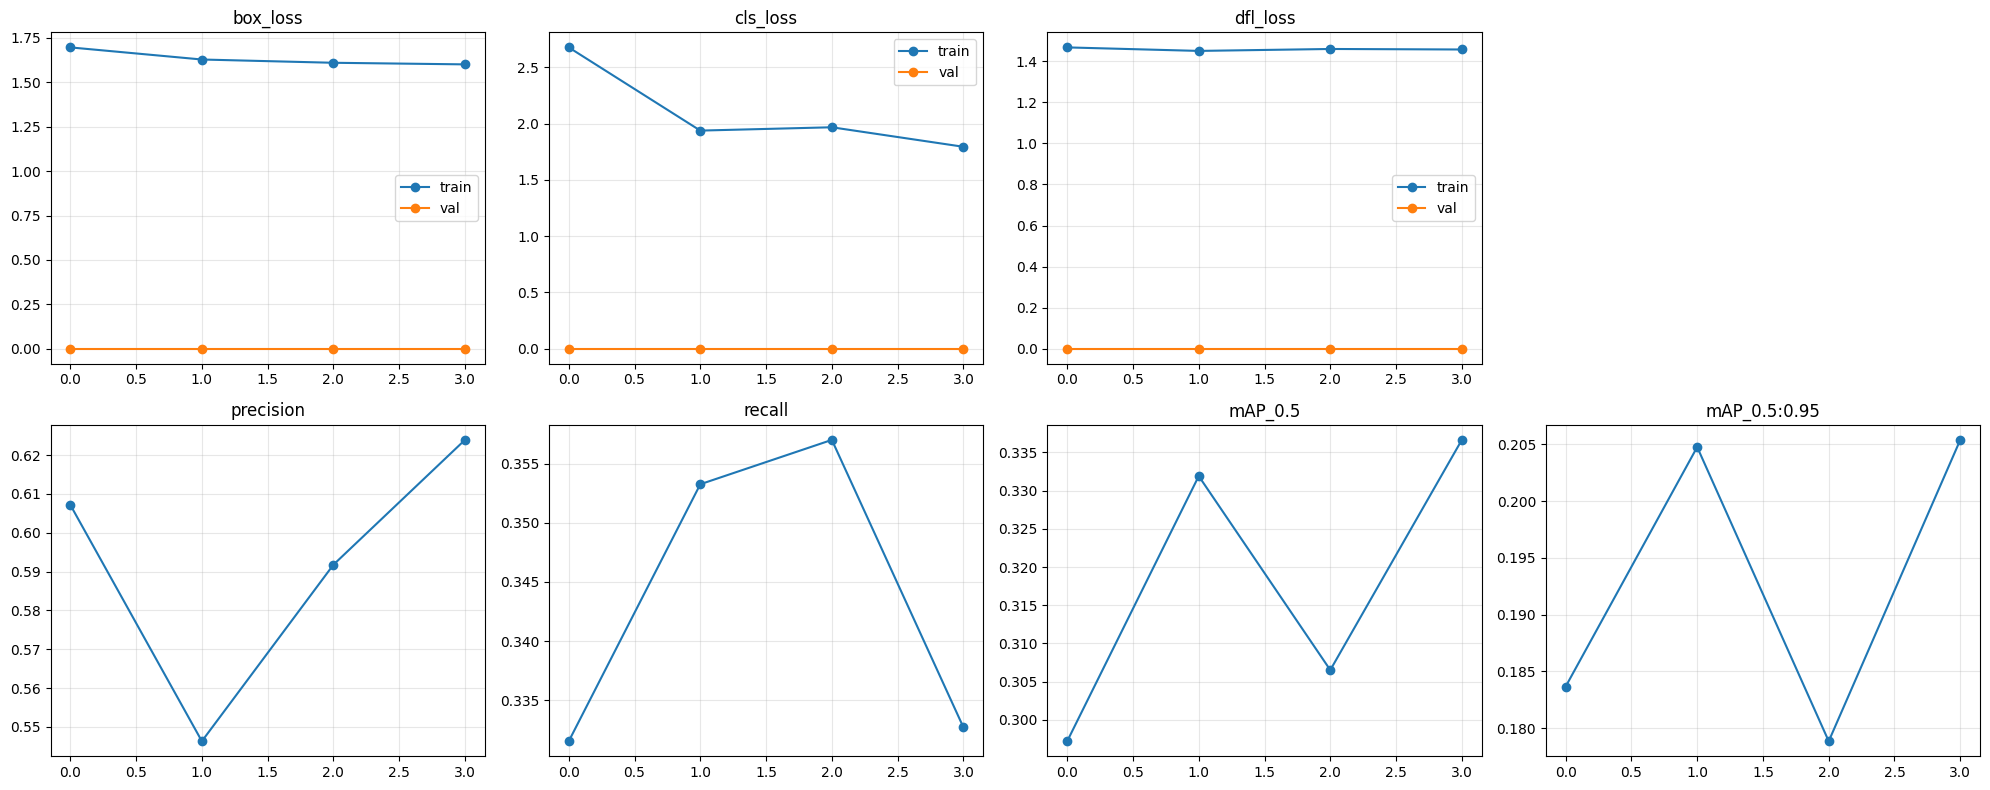

In [71]:
import pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv(RUN / "results.csv")
df.columns = df.columns.str.strip()
display(df.round(4))

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, k in zip(axes[0][:3], ["box_loss", "cls_loss", "dfl_loss"]):
    ax.plot(df["epoch"], df[f"train/{k}"], marker="o", label="train")
    ax.plot(df["epoch"], df[f"val/{k}"], marker="o", label="val")
    ax.set_title(k); ax.legend(); ax.grid(alpha=.3)
axes[0][3].axis("off")
for ax, k in zip(axes[1], ["metrics/precision", "metrics/recall",
                           "metrics/mAP_0.5", "metrics/mAP_0.5:0.95"]):
    ax.plot(df["epoch"], df[k], marker="o")
    ax.set_title(k.split("/")[1]); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## matrice de confusion générées par YOLO

results.png


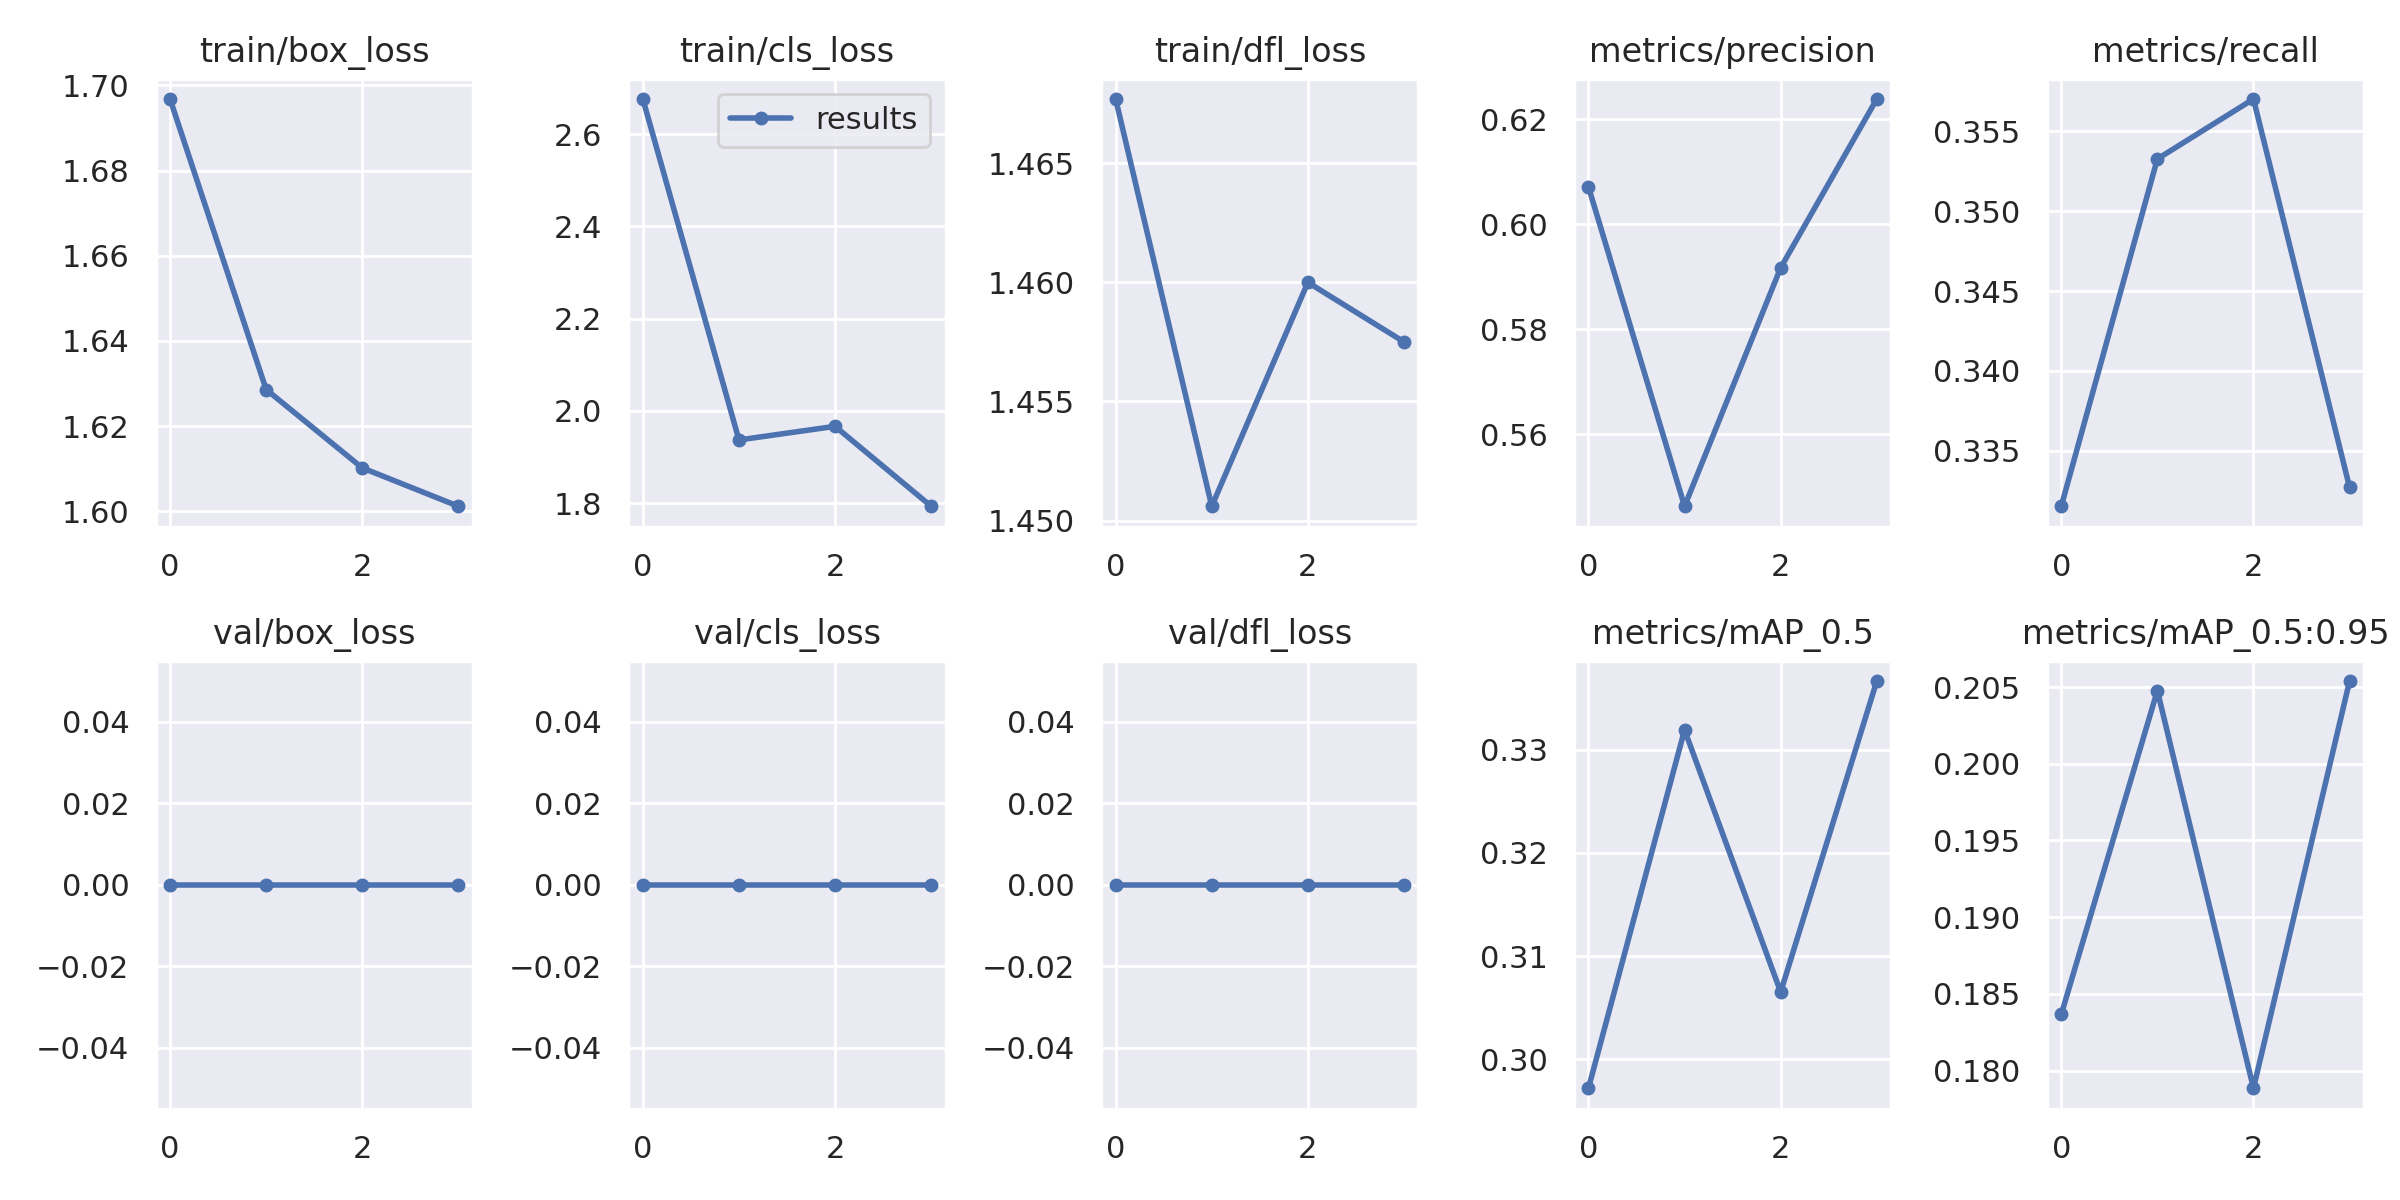

confusion_matrix.png


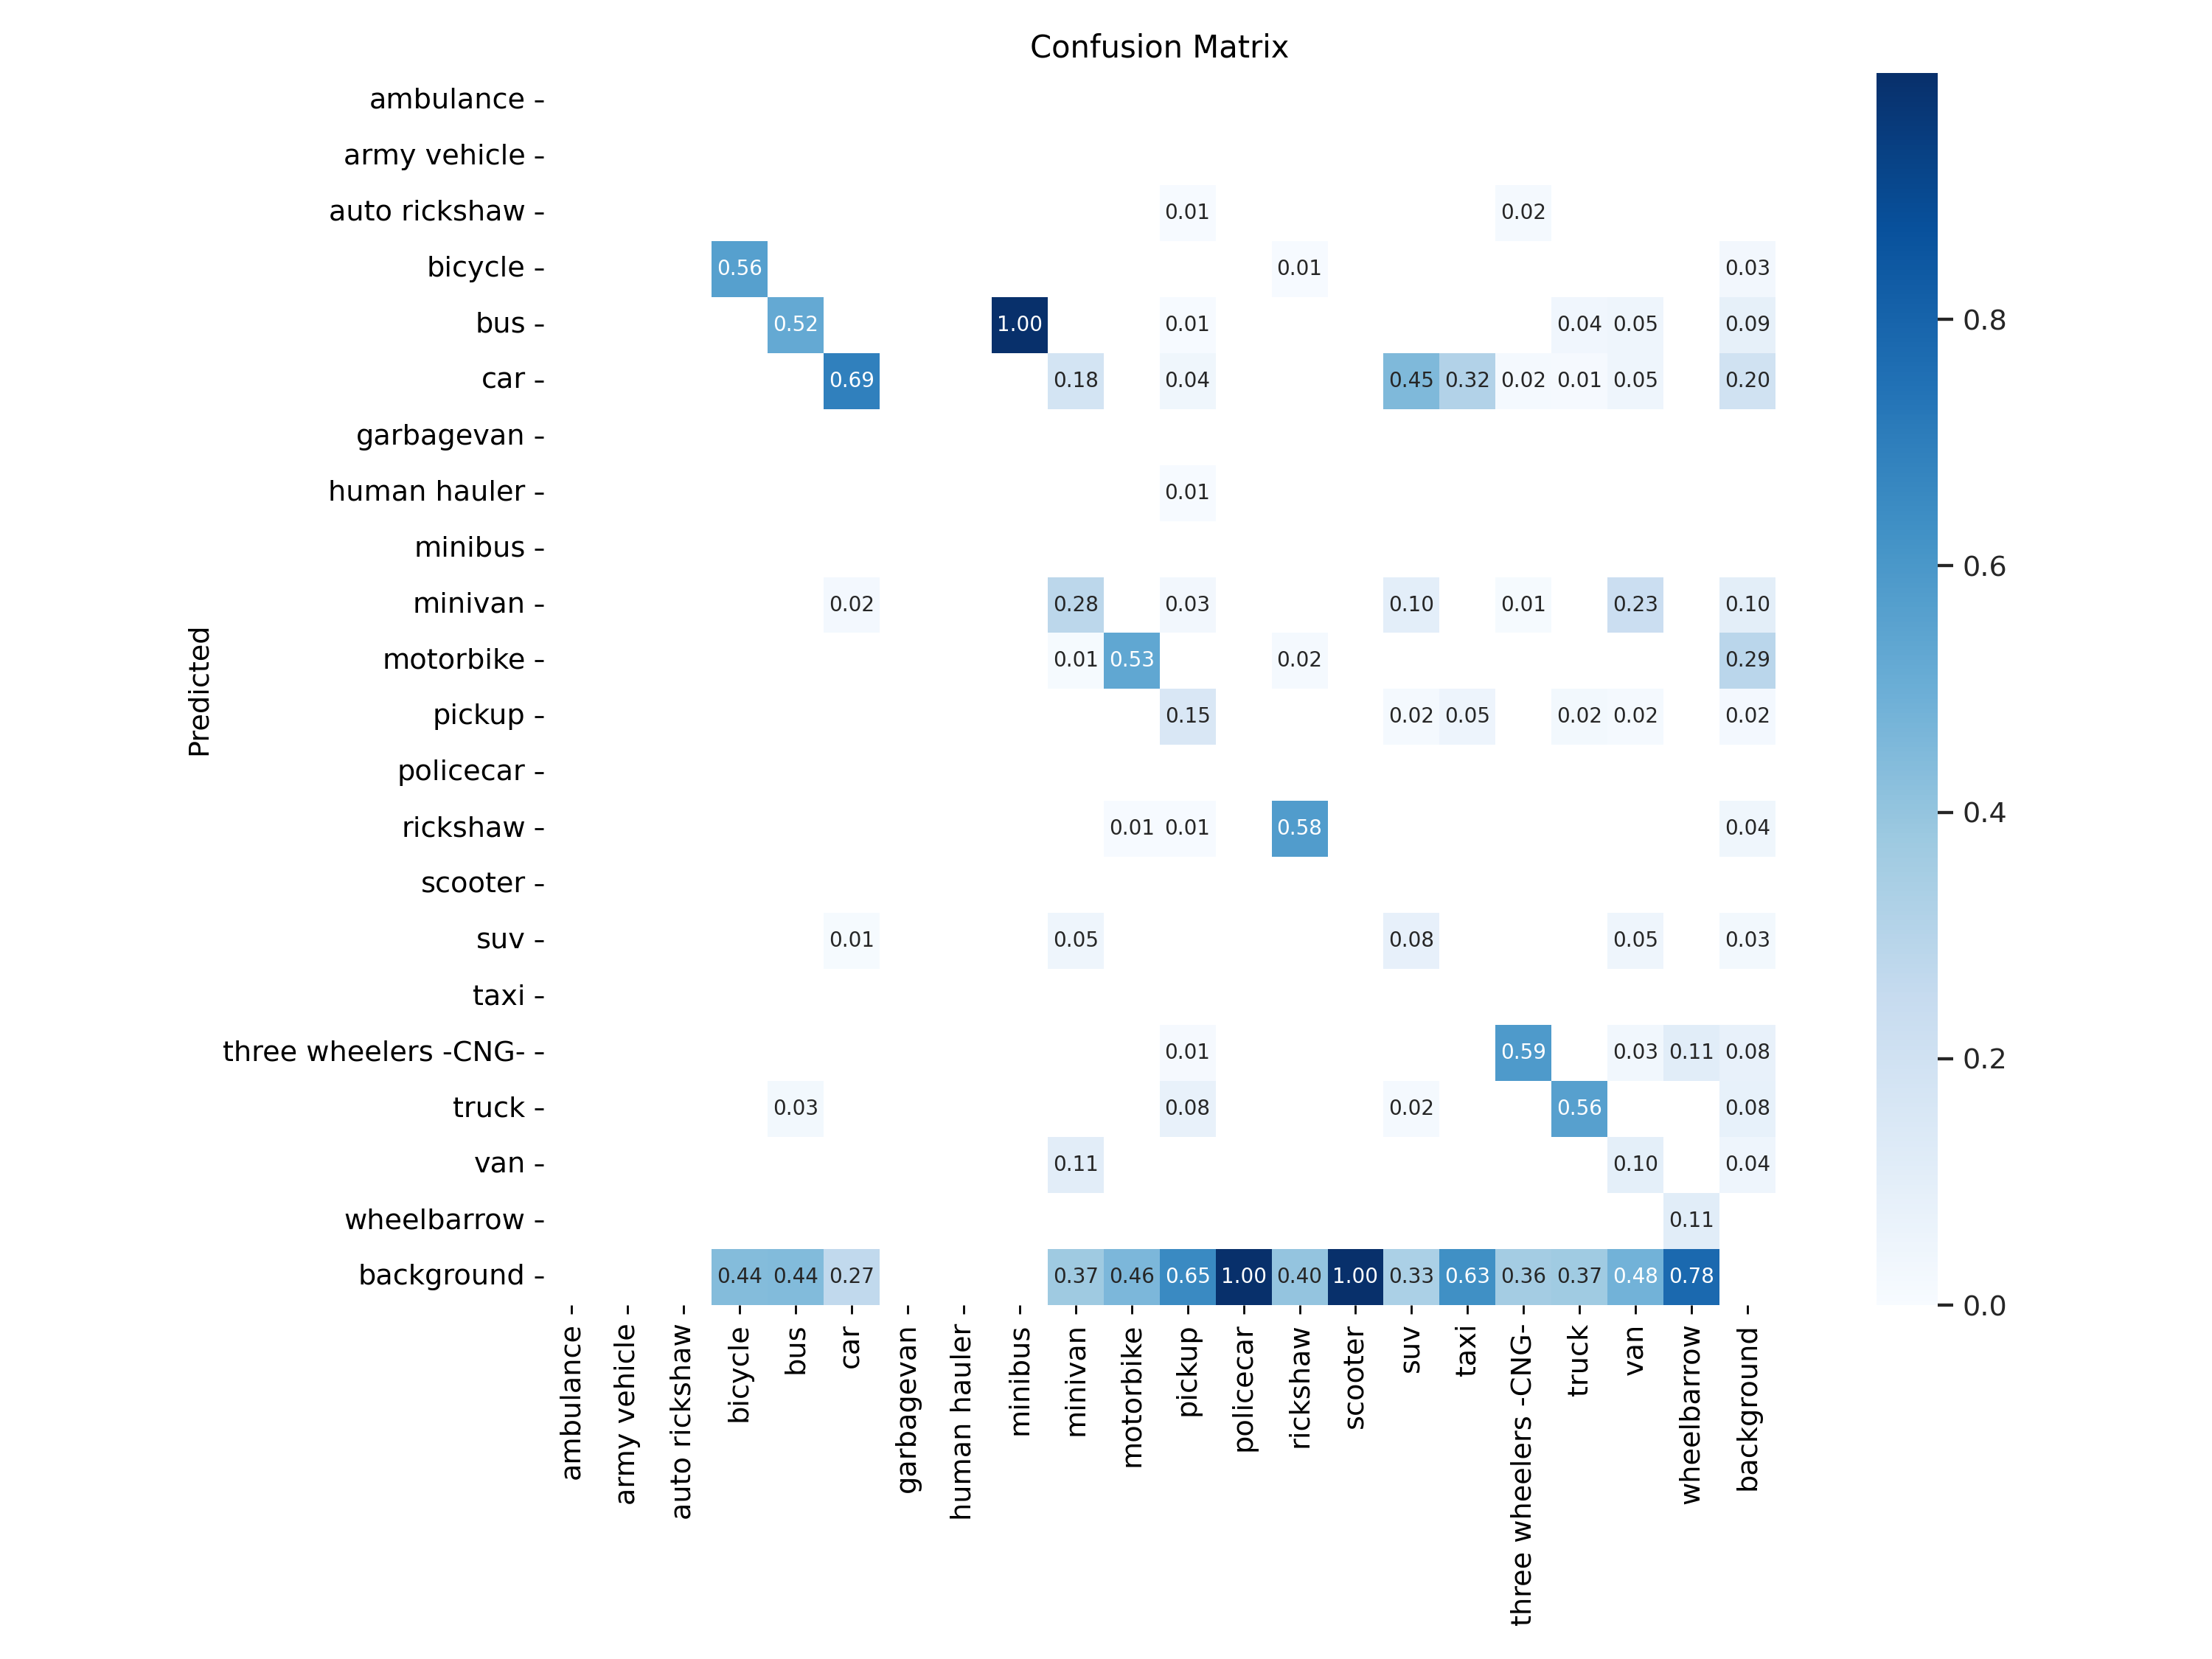

PR_curve.png


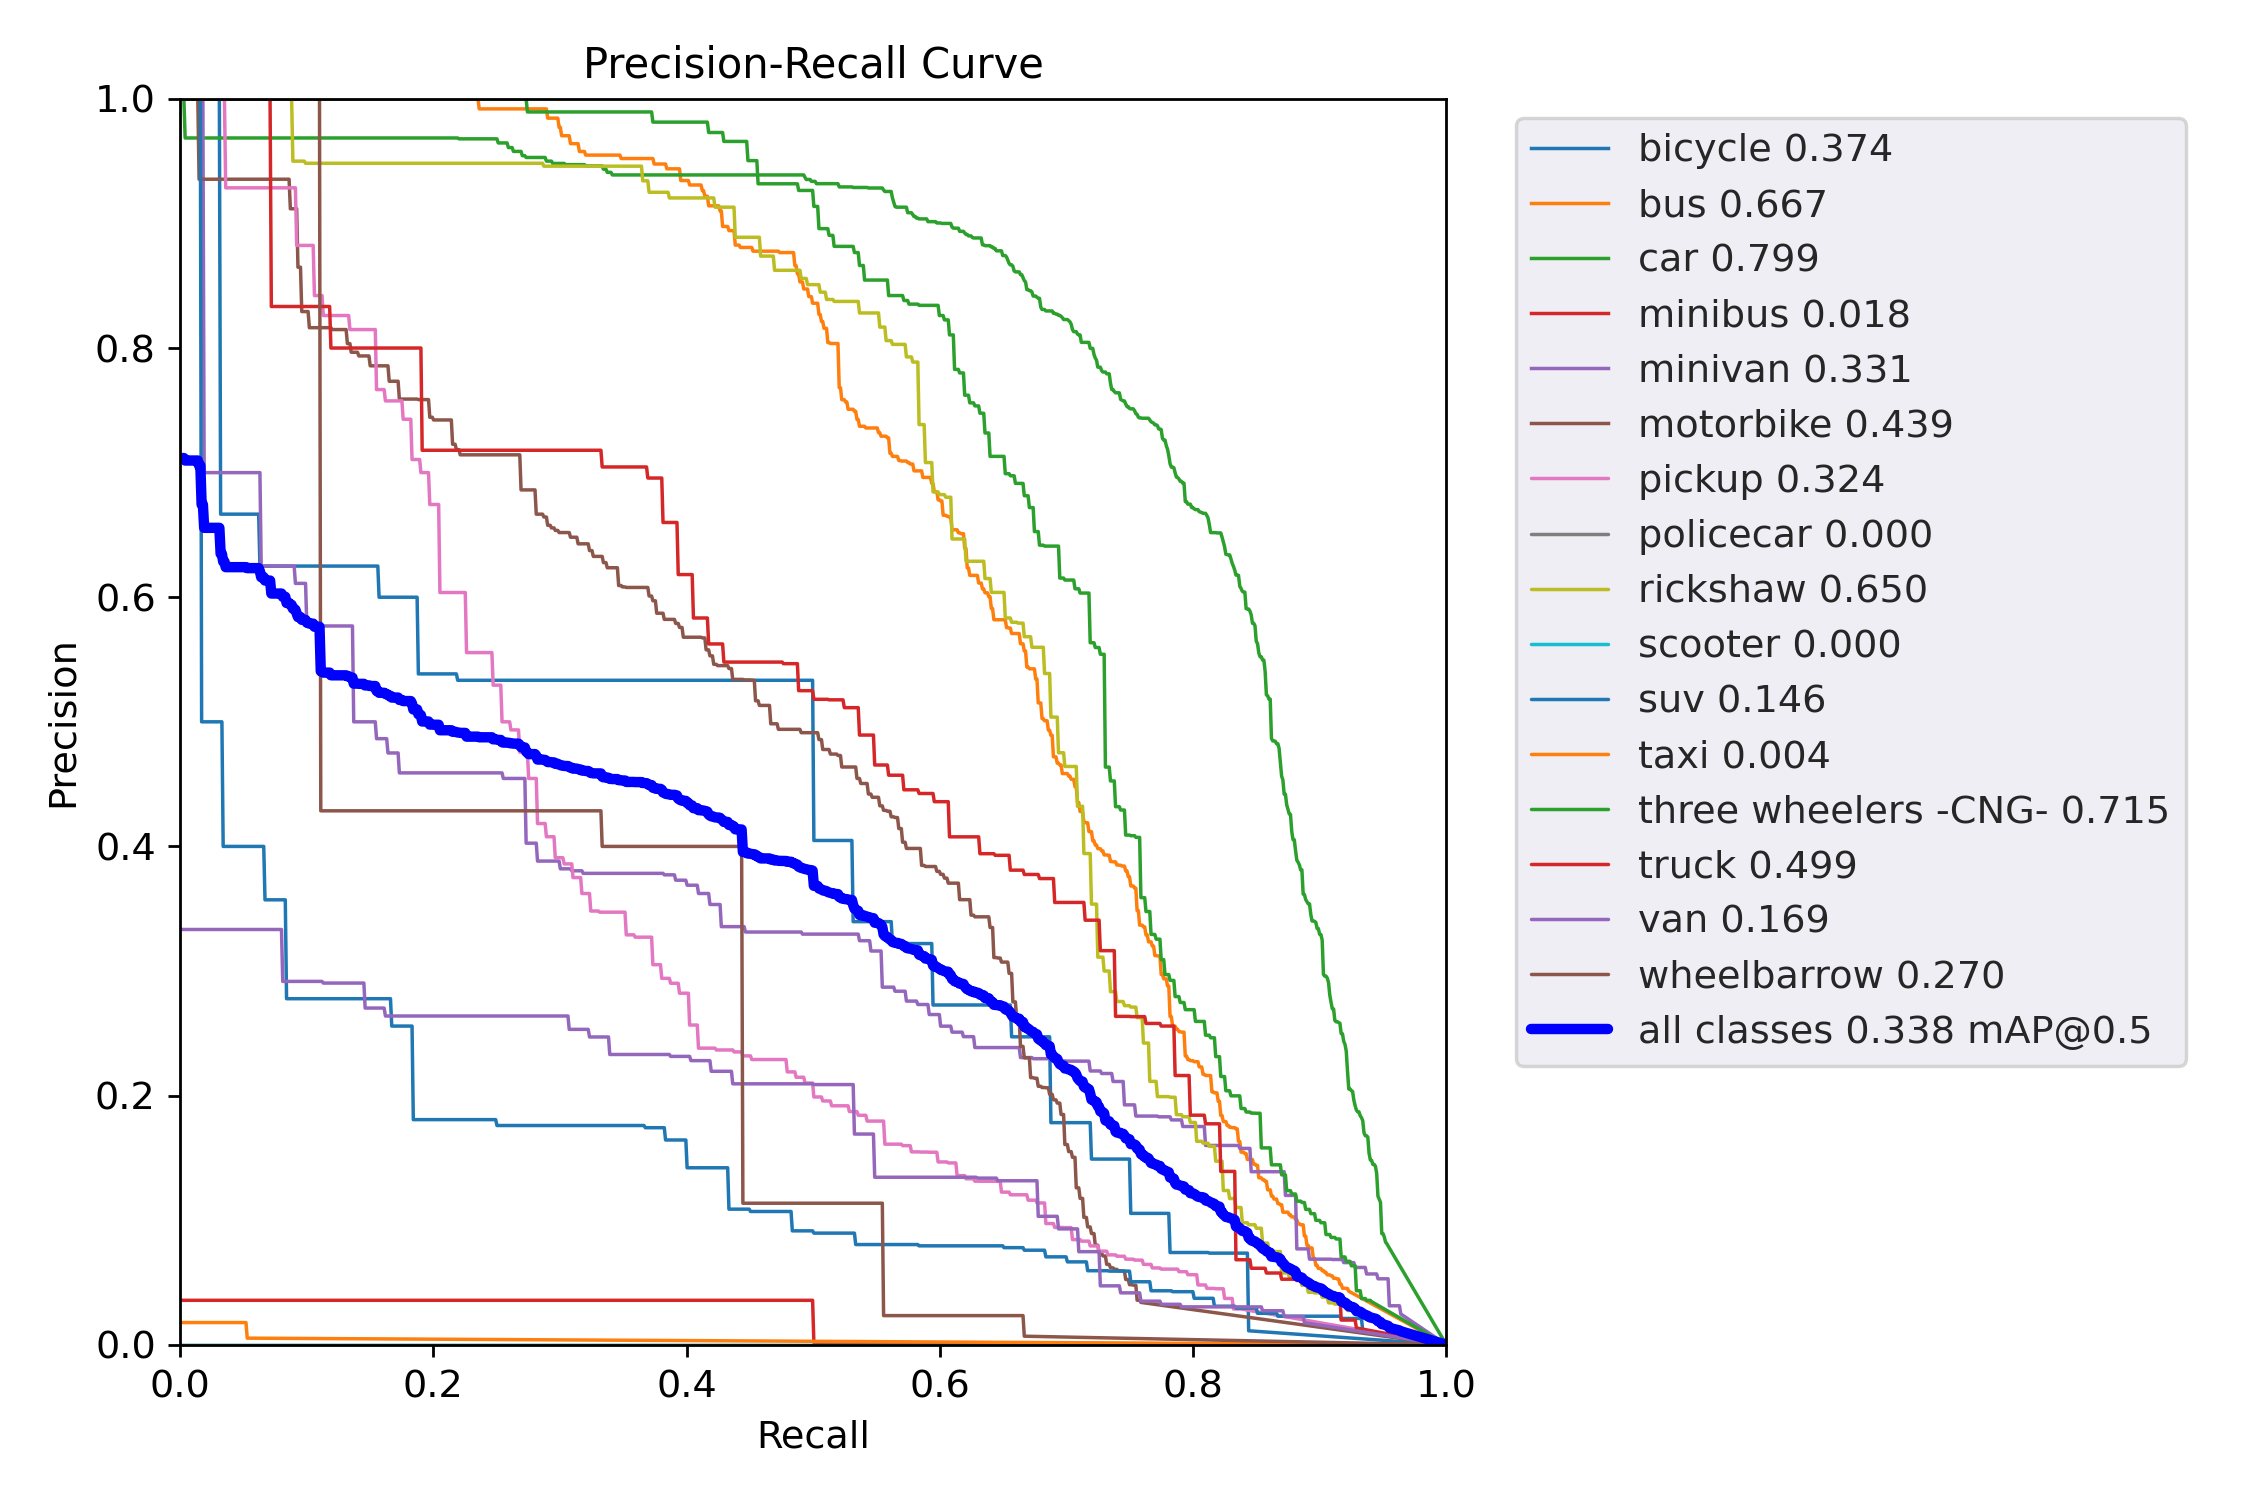

In [72]:
from IPython.display import Image, display
for name in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    print(name)
    display(Image(filename=str(RUN / name), width=900))

### Identifier les poids

In [73]:
for p in sorted((RUN / "weights").glob("*.pt")):
    print(f"{p.name:10s} {p.stat().st_size / 1e6:.1f} MB")

fitness = 0.1 * df["metrics/mAP_0.5"] + 0.9 * df["metrics/mAP_0.5:0.95"]
print("\nMeilleur epoch (best.pt) :", int(df.loc[fitness.idxmax(), "epoch"]))
print("Dernier epoch  (last.pt) :", int(df["epoch"].iloc[-1]))

best.pt    102.8 MB
last.pt    102.8 MB

Meilleur epoch (best.pt) : 3
Dernier epoch  (last.pt) : 3


## predictions (val)

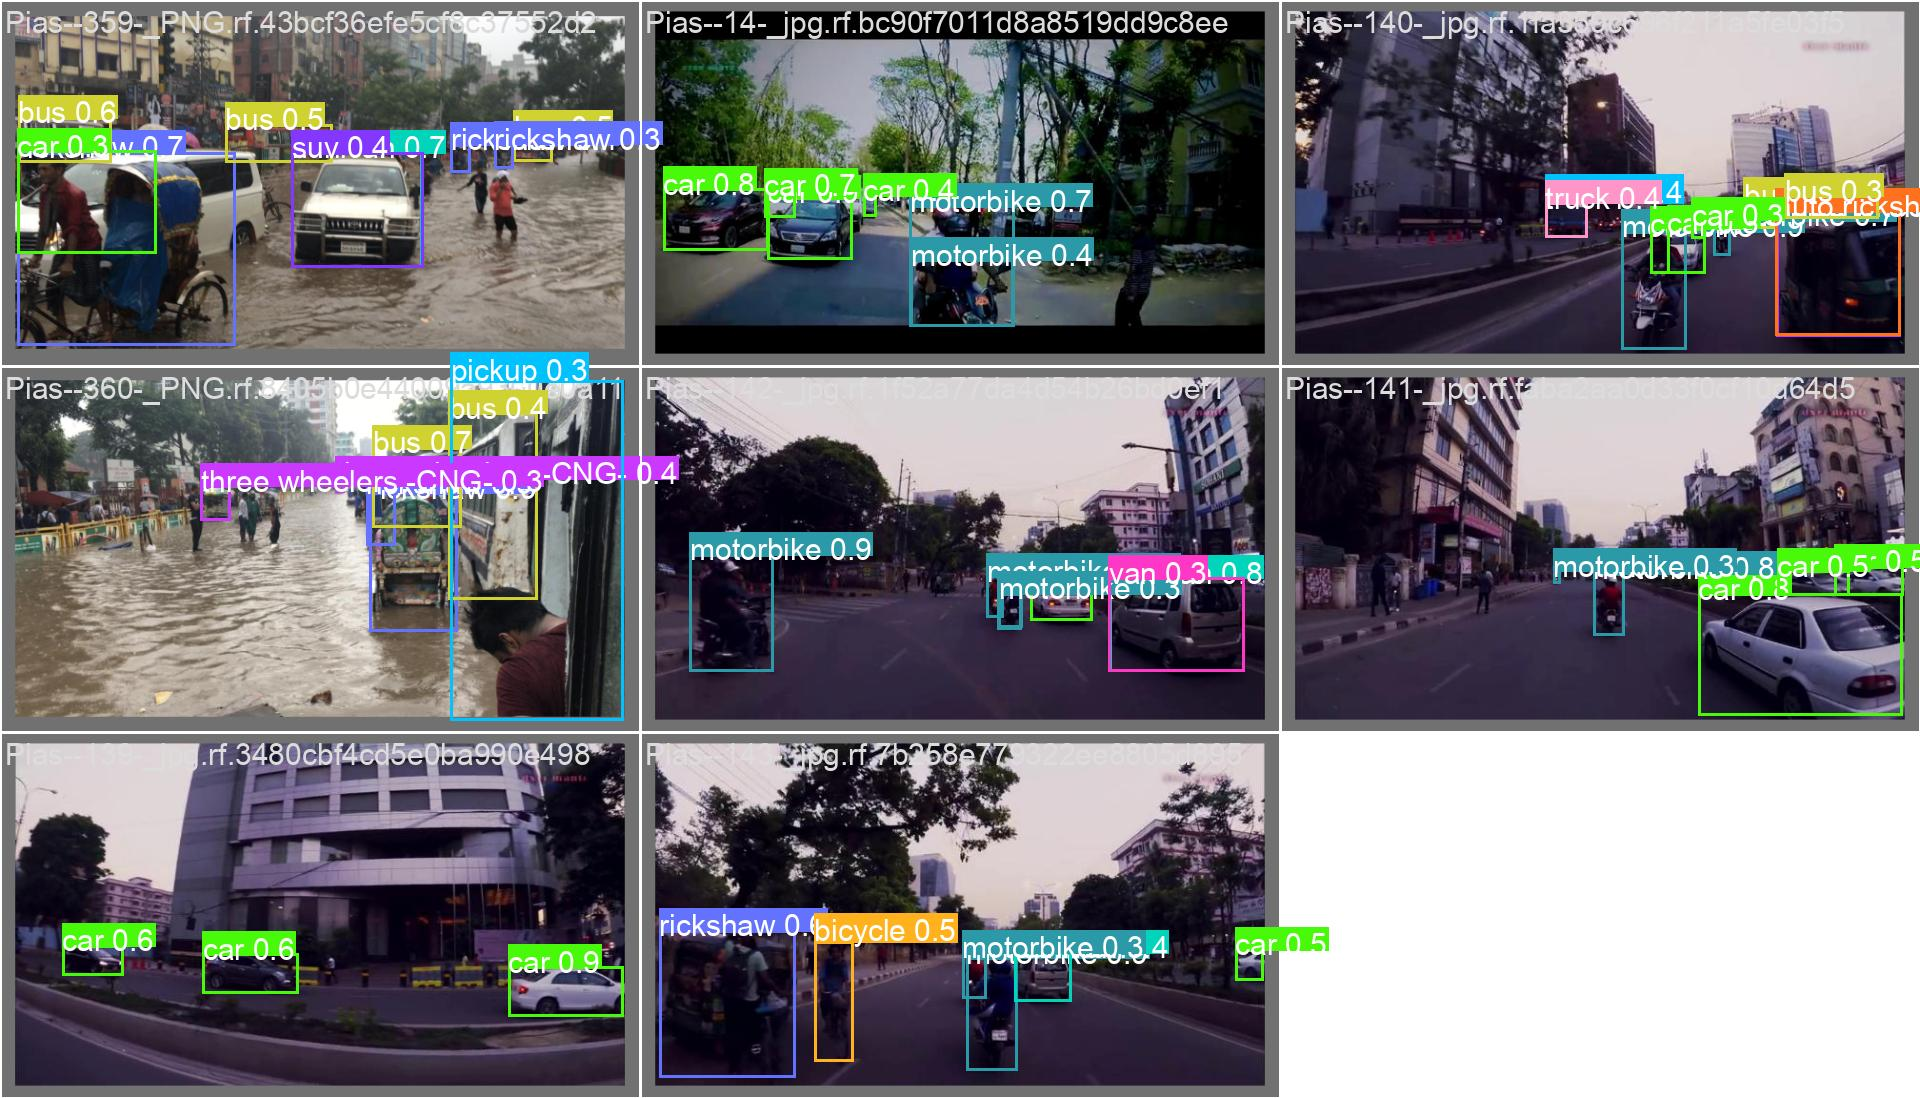

In [76]:
from IPython.display import Image, display

display(Image(filename=str(RUN / "val_batch0_pred.jpg"), width=1000))

val_batch0_labels.jpg


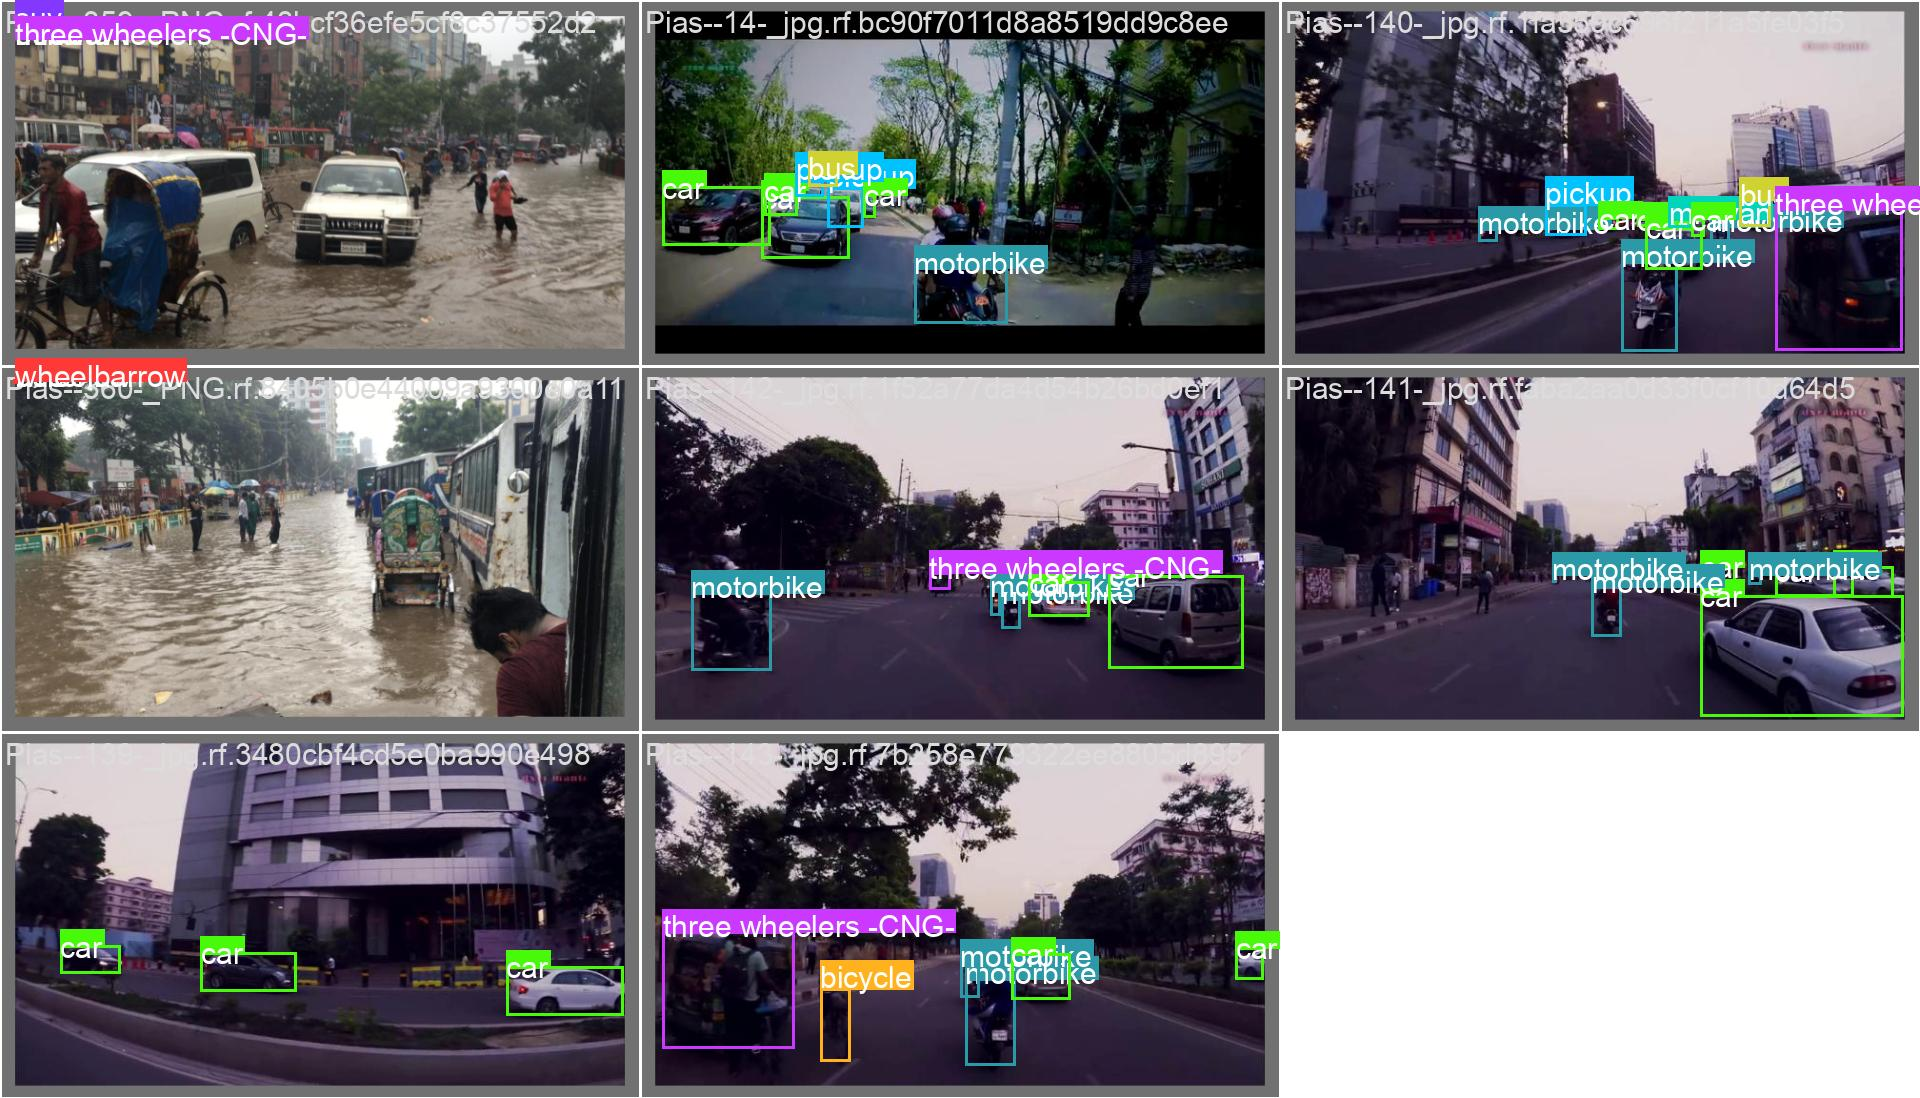

val_batch0_pred.jpg


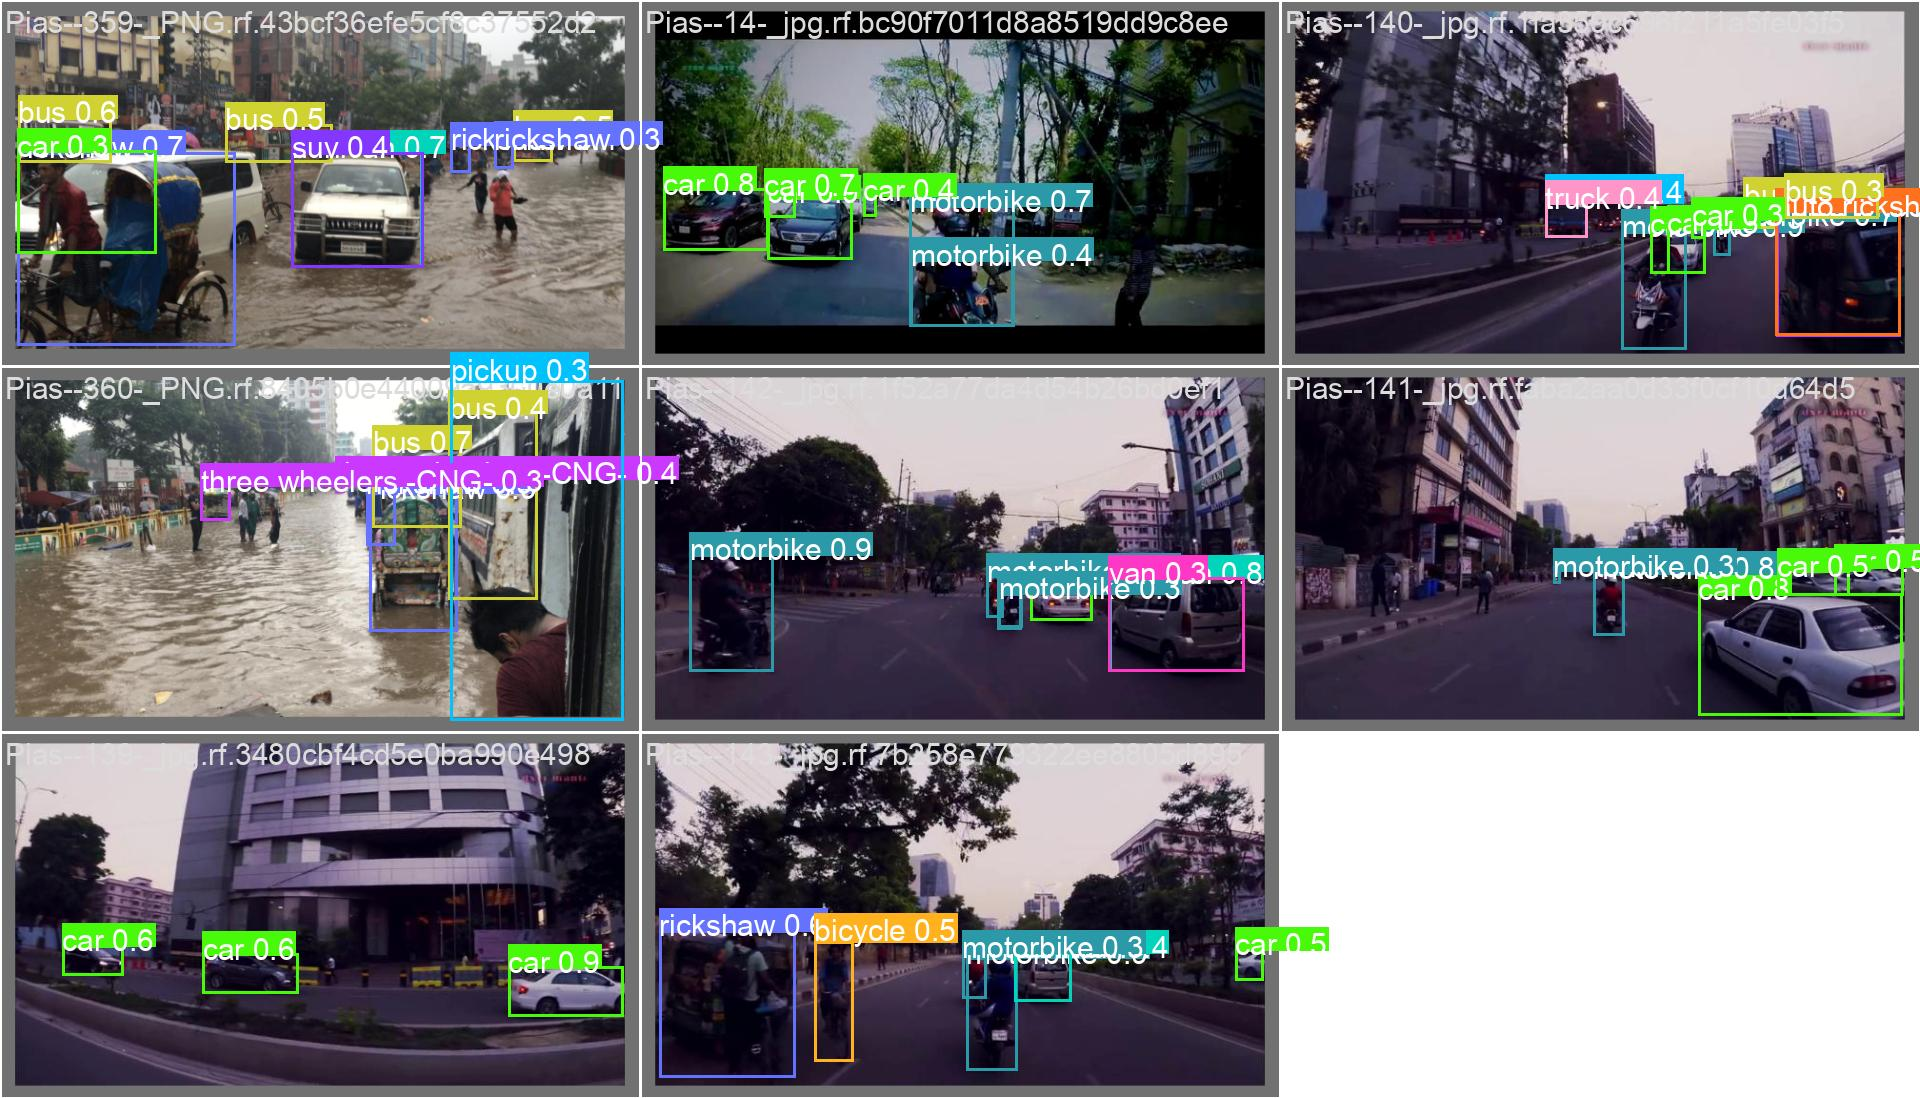

In [77]:
for name in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    print(name)
    display(Image(filename=str(RUN / name), width=1000))